# Social Anxiety: Data Cleaning & Exploratory Analysis

This notebook takes a social anxiety dataset (about 2,000 people, 22 columns) from a messy CSV all the way to statistical tests. The question is simple: which lifestyle, physiological and demographic factors go hand in hand with being labelled anxious (`is_Anxious`)?

Here's the plan:

1. Clean the data: duplicates, impossible values, outliers, missing values.
2. Build a few new features and turn some numbers into meaningful ranges.
3. Look at every variable against the target, charts first, tests second.
4. Look at pairs of variables together, to see if they tell a different story combined.

One thing to keep in mind throughout: everything here is about association, not cause and effect.

In [1]:
import os
import re
import textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from plotly import express  as px
from plotly import subplots
from plotly import graph_objects as go
import plotly.io as pio
from scipy import stats as sps
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from scipy.stats import chi2
from scipy.stats import chi2_contingency
from scipy.stats import shapiro

## Saving figures

Every chart in this notebook goes through `save_figure`. With `SAVE_FIGURES = True`, a copy of each chart lands in the `figures/` folder. Plotly charts are saved as PNG when `kaleido` is installed and working; otherwise they fall back to interactive HTML files.

GitHub doesn't render interactive Plotly charts, so they show up as blank space there. Set `STATIC_PLOTS = True` before the final run if you want the notebook itself to show static images instead.

In [2]:
SAVE_FIGURES = True
STATIC_PLOTS = False
FIGURES_DIR = "figures"

if SAVE_FIGURES:
    os.makedirs(FIGURES_DIR, exist_ok=True)

if STATIC_PLOTS:
    pio.renderers.default = "png"
    pio.renderers["png"].width = 1300
    pio.renderers["png"].height = 500


def save_figure(fig, name):

    if not SAVE_FIGURES:
        return

    file_name = re.sub(r"[^\w\-]+", "_", name).strip("_").lower()
    path = os.path.join(FIGURES_DIR, file_name)

    if isinstance(fig, go.Figure):
        try:
            fig.write_image(
                path + ".png",
                width=fig.layout.width or 1400,
                height=fig.layout.height or 500,
                scale=2
            )
        except Exception as error:
            fig.write_html(path + ".html", include_plotlyjs="cdn")
            if not getattr(save_figure, "warned", False):
                print("PNG export failed, saving Plotly figures as HTML instead:", error)
                save_figure.warned = True
    else:
        fig.savefig(path + ".png", dpi=150, bbox_inches="tight")

# Loading the data

In [3]:
dataframe = pd.read_csv("social_anxiety_dataset.csv")

# First look

Before touching anything, let's see what we're working with: the shape, column types, basic stats, and how much is missing in each column.

In [4]:
pd.set_option("display.max_columns", None)
dataframe.head()

,Age,Gender,Occupation,Sleep Hours,Physical Activity (hrs/week),Caffeine Intake (mg/day),Alcohol Consumption (drinks/week),Smoking,Family History of Anxiety,Stress Level (1-10),Heart Rate (bpm),Breathing Rate (breaths/min),Sweating Level (1-5),Dizziness,Medication,Therapy Sessions (per month),Recent Major Life Event,Diet Quality (1-10),Anxiety Level (1-10),Target,is_Anxious,Therapy History
0,59.0,Other,Teacher,7.0,2.4,40.0,5,Yes,No,4,79,21,5,No,No,0,Yes,1.0,2.0,0,0,Group Therapy
1,46.0,Female,Student,5.1,5.4,156.0,11,NaN,No,3,70,19,4,Yes,No,2,No,1.0,4.0,0,0,NaN
2,40.0,Other,Lawyer,5.1,1.9,570.0,14,Yes,Yes,9,101,23,3,No,No,6,Yes,4.0,9.0,1,1,NaN
3,40.0,Male,Nurse,7.6,0.9,129.0,0,No,No,9,116,16,2,No,NaN,2,No,2.0,6.0,0,0,NaN
4,26.0,Male,Other,6.7,3.0,64.0,13,No,No,15,119,19,4,No,Yes,0,Yes,4.0,3.0,0,0,NaN


In [5]:
dataframe.shape

(2030, 22)

In [6]:
dataframe.info()

<class 'pandas.DataFrame'>
RangeIndex: 2030 entries, 0 to 2029
Data columns (total 22 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Age                                1968 non-null   float64
 1   Gender                             1911 non-null   str    
 2   Occupation                         2030 non-null   str    
 3   Sleep Hours                        1994 non-null   float64
 4   Physical Activity (hrs/week)       2030 non-null   float64
 5   Caffeine Intake (mg/day)           1936 non-null   float64
 6   Alcohol Consumption (drinks/week)  2030 non-null   int64  
 7   Smoking                            1924 non-null   str    
 8   Family History of Anxiety          2030 non-null   str    
 9   Stress Level (1-10)                2030 non-null   int64  
 10  Heart Rate (bpm)                   2030 non-null   int64  
 11  Breathing Rate (breaths/min)       2030 non-null   int64  
 12  Swe

In [7]:
dataframe.describe()

,Age,Sleep Hours,Physical Activity (hrs/week),Caffeine Intake (mg/day),Alcohol Consumption (drinks/week),Stress Level (1-10),Heart Rate (bpm),Breathing Rate (breaths/min),Sweating Level (1-5),Therapy Sessions (per month),Diet Quality (1-10),Anxiety Level (1-10),Target,is_Anxious
count,1968.000000,1994.000000,2030.000000,1936.000000,2030.000000,2030.000000,2030.000000,2030.000000,2030.000000,2030.000000,1952.000000,2030.000000,2030.000000,2030.000000
mean,39.921748,6.424624,2.800246,306.275826,9.490148,6.028571,93.066502,20.955665,3.095567,2.359113,5.234119,3.922660,0.103448,0.103448
std,13.243754,2.161544,2.233899,208.012717,6.028653,3.137269,23.313430,5.182524,1.392697,2.148642,2.884946,2.139176,0.304619,0.304619
min,18.000000,-10.000000,-10.000000,0.000000,-10.000000,1.000000,60.000000,12.000000,1.000000,0.000000,1.000000,1.000000,0.000000,0.000000
25%,29.000000,5.800000,1.400000,177.750000,5.000000,3.000000,76.000000,17.000000,2.000000,1.000000,3.000000,2.000000,0.000000,0.000000
50%,40.000000,6.700000,2.800000,277.500000,10.000000,6.000000,93.000000,21.000000,3.000000,2.000000,5.000000,4.000000,0.000000,0.000000
75%,51.000000,7.500000,4.200000,391.000000,15.000000,9.000000,107.000000,26.000000,4.000000,3.000000,8.000000,5.000000,0.000000,0.000000
max,64.000000,11.000000,9.200000,1500.000000,19.000000,15.000000,220.000000,29.000000,5.000000,10.000000,10.000000,10.000000,1.000000,1.000000


In [8]:
print(round((dataframe.isnull().sum() / len(dataframe)) * 100 , 3))

Age                                   3.054
Gender                                5.862
Occupation                            0.000
Sleep Hours                           1.773
Physical Activity (hrs/week)          0.000
Caffeine Intake (mg/day)              4.631
Alcohol Consumption (drinks/week)     0.000
Smoking                               5.222
Family History of Anxiety             0.000
Stress Level (1-10)                   0.000
Heart Rate (bpm)                      0.000
Breathing Rate (breaths/min)          0.000
Sweating Level (1-5)                  0.000
Dizziness                             0.000
Medication                            5.369
Therapy Sessions (per month)          0.000
Recent Major Life Event               0.000
Diet Quality (1-10)                   3.842
Anxiety Level (1-10)                  0.000
Target                                0.000
is_Anxious                            0.000
Therapy History                      90.000
dtype: float64


# Duplicates

No duplicate rows, which is good news. Columns are another story: `Target` turns out to be an exact copy of `is_Anxious`. We drop it and keep `is_Anxious` as our label.

In [9]:
print("Duplicate rows:", dataframe.duplicated().sum())

Duplicate rows: 0


In [10]:
def find_duplicate_columns(df):
    duplicate_columns = []

    for i in range(len(df.columns)):
        for j in range(i + 1, len(df.columns)):
            col1 = df.columns[i]
            col2 = df.columns[j]

            if df[col1].equals(df[col2]):
                duplicate_columns.append((col1, col2))

    return duplicate_columns

duplicate_columns = find_duplicate_columns(dataframe)
print(duplicate_columns)

[('Target', 'is_Anxious')]


In [11]:
dataframe = dataframe.drop(columns=["Target"])

# Dropping rows that are mostly empty

A row missing more than four values doesn't give us much to work with, so it goes. In practice this only removes one row.

In [12]:
def remove_rows_with_many_missing(df, max_missing=4):
    missing_count = df.isnull().sum(axis=1)
    df = df[missing_count <= max_missing]
    return df

dataframe = remove_rows_with_many_missing(dataframe)

In [13]:
dataframe.shape

(2029, 21)

# Sorting the columns by type

Different kinds of columns need different handling, so we split them into three groups: numeric (continuous values and counts), ordinal (the 1–10 and 1–5 scales) and categorical.

In [14]:
numeric_columns = [
    "Age",
    "Sleep Hours",
    "Physical Activity (hrs/week)",
    "Caffeine Intake (mg/day)",
    "Alcohol Consumption (drinks/week)",
    "Heart Rate (bpm)",
    "Breathing Rate (breaths/min)",
    "Therapy Sessions (per month)"
]

ordinal_columns = [
    "Stress Level (1-10)",
    "Sweating Level (1-5)",
    "Diet Quality (1-10)",
    "Anxiety Level (1-10)"
]

categorical_columns = [
    "Gender",
    "Occupation",
    "Therapy History",
    "Smoking",
    "Family History of Anxiety",
    "Dizziness",
    "Medication",
    "Recent Major Life Event",
    "is_Anxious"
]

# Numeric columns before cleaning

Histograms and boxplots of the raw numeric columns. This is where the weird stuff shows up: negative hours of sleep, negative drinks per week, a heart rate of 220.

In [15]:
def plot_histograms(data, columns, title="Numerical Distributions - Before Cleaning"):

    rows = (len(columns) + 2) // 3

    fig, axes = plt.subplots(rows, 3, figsize=(15, 4 * rows))
    axes = axes.flatten()

    for i, col in enumerate(columns):

        axes[i].hist(
            data[col].dropna(),
            bins=20,
            color="#9D5D6A"
        )

        axes[i].set_title(col, fontsize=12)

        axes[i].set_facecolor("#ACBDCB")


        axes[i].grid(
            axis="y",
            color="white",
            linewidth=1
        )

        axes[i].set_axisbelow(True)

        axes[i].locator_params(axis="x", nbins=5)
        axes[i].locator_params(axis="y", nbins=5)

        axes[i].spines["top"].set_visible(False)
        axes[i].spines["right"].set_visible(False)
        axes[i].spines["left"].set_visible(False)
        axes[i].spines["bottom"].set_visible(False)

    for i in range(len(columns), len(axes)):
        axes[i].set_visible(False)

    plt.suptitle(
        title,
        fontsize=16
    )

    plt.subplots_adjust(
        hspace=0.55,
        wspace=0.30,
        top=0.90
    )

    save_figure(fig, title)

    plt.show()

In [16]:
plot_histograms(dataframe, numeric_columns)

<Figure size 1500x1200 with 9 Axes>

In [17]:
def plot_boxplots(data, columns, title="Numerical Boxplots - Before Cleaning"):

    rows = (len(columns) + 2) // 3

    fig, axes = plt.subplots(rows, 3, figsize=(15, 4 * rows))
    axes = axes.flatten()

    for i, col in enumerate(columns):

        axes[i].boxplot(
            data[col].dropna(),
            vert=True,
            patch_artist=True,
            boxprops=dict(
                facecolor="#D8A7B1",
                color="#7A3E4A",
                linewidth=1.5),
            medianprops=dict(
                color="#4A1F27",
                linewidth=2),
            whiskerprops=dict(
                color="#7A3E4A",
                linewidth=1.3),
            flierprops=dict(
                marker="o",
                markerfacecolor="#B66A76",
                markeredgecolor="#7A3E4A",
                markersize=4,
                alpha=0.6)
        )

        axes[i].set_title(col, fontsize=12)

        axes[i].set_facecolor("#ACBDCB")

        axes[i].grid(
            axis="y",
            color="white",
            linewidth=1
        )

        axes[i].set_axisbelow(True)
        axes[i].locator_params(axis="y", nbins=5)

        axes[i].set_xticks([])

        axes[i].spines["top"].set_visible(False)
        axes[i].spines["right"].set_visible(False)
        axes[i].spines["left"].set_visible(False)
        axes[i].spines["bottom"].set_visible(False)

    for i in range(len(columns), len(axes)):
        axes[i].set_visible(False)

    plt.suptitle(
        title,
        fontsize=16
    )

    plt.subplots_adjust(
        hspace=0.55,
        wspace=0.30,
        top=0.90
    )

    save_figure(fig, title)

    plt.show()

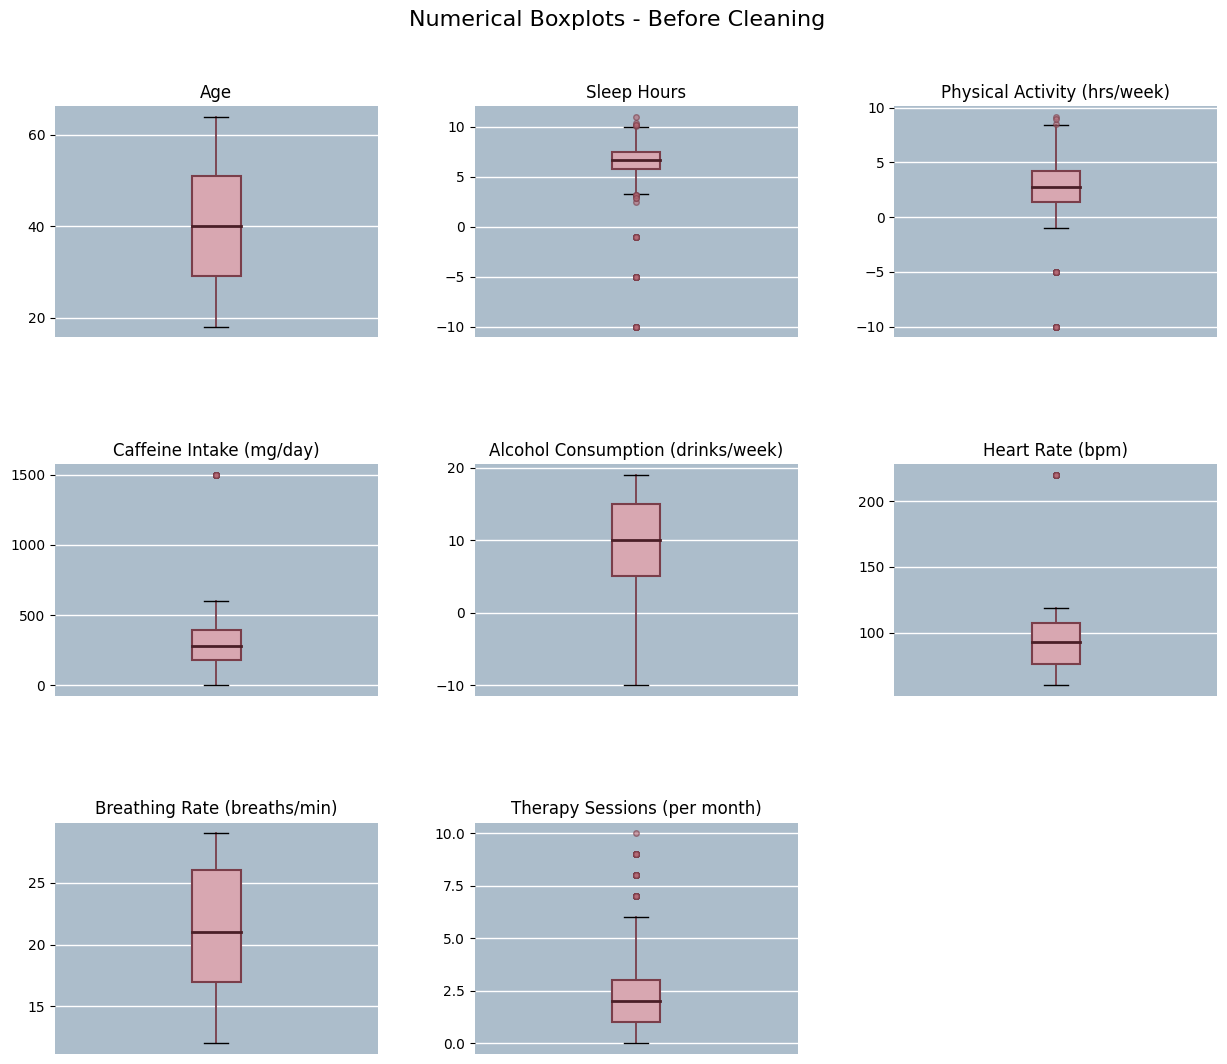

In [18]:
plot_boxplots(dataframe, numeric_columns)

# Categorical columns

Same idea for the ordinal and categorical columns. Missing values are included, so the gaps are visible too.

In [19]:
bar_columns = ordinal_columns + categorical_columns 
def plot_bar_charts(data, columns):

    rows = (len(columns) + 2) // 3

    fig, axes = plt.subplots(rows, 3, figsize=(18, 5 * rows))
    axes = axes.flatten()

    for i, col in enumerate(columns):

        counts = data[col].value_counts(dropna=False).sort_index()

        labels = [
            "\n".join(textwrap.wrap(str(x), width=18))
            for x in counts.index
        ]

        axes[i].barh(
            labels,
            counts.values,
            color="#B66A76",
            edgecolor="#7A3E4A",
            linewidth=0.8
        )

        axes[i].set_title(col, fontsize=12)

        axes[i].set_facecolor("#ACBDCB")

        axes[i].grid(
            axis="x",
            color="white",
            linewidth=1.2
        )

        axes[i].set_axisbelow(True)
        axes[i].locator_params(axis="x", nbins=5)

        axes[i].tick_params(axis="y", labelsize=8)

        axes[i].spines["top"].set_visible(False)
        axes[i].spines["right"].set_visible(False)
        axes[i].spines["left"].set_visible(False)
        axes[i].spines["bottom"].set_visible(False)

    for i in range(len(columns), len(axes)):
        axes[i].set_visible(False)

    plt.suptitle(
        "Categorical Distributions - Before Cleaning",
        fontsize=16
    )

    plt.subplots_adjust(
        hspace=0.65,
        wspace=0.55,
        top=0.93
    )

    save_figure(fig, "Categorical Distributions - Before Cleaning")

    plt.show()

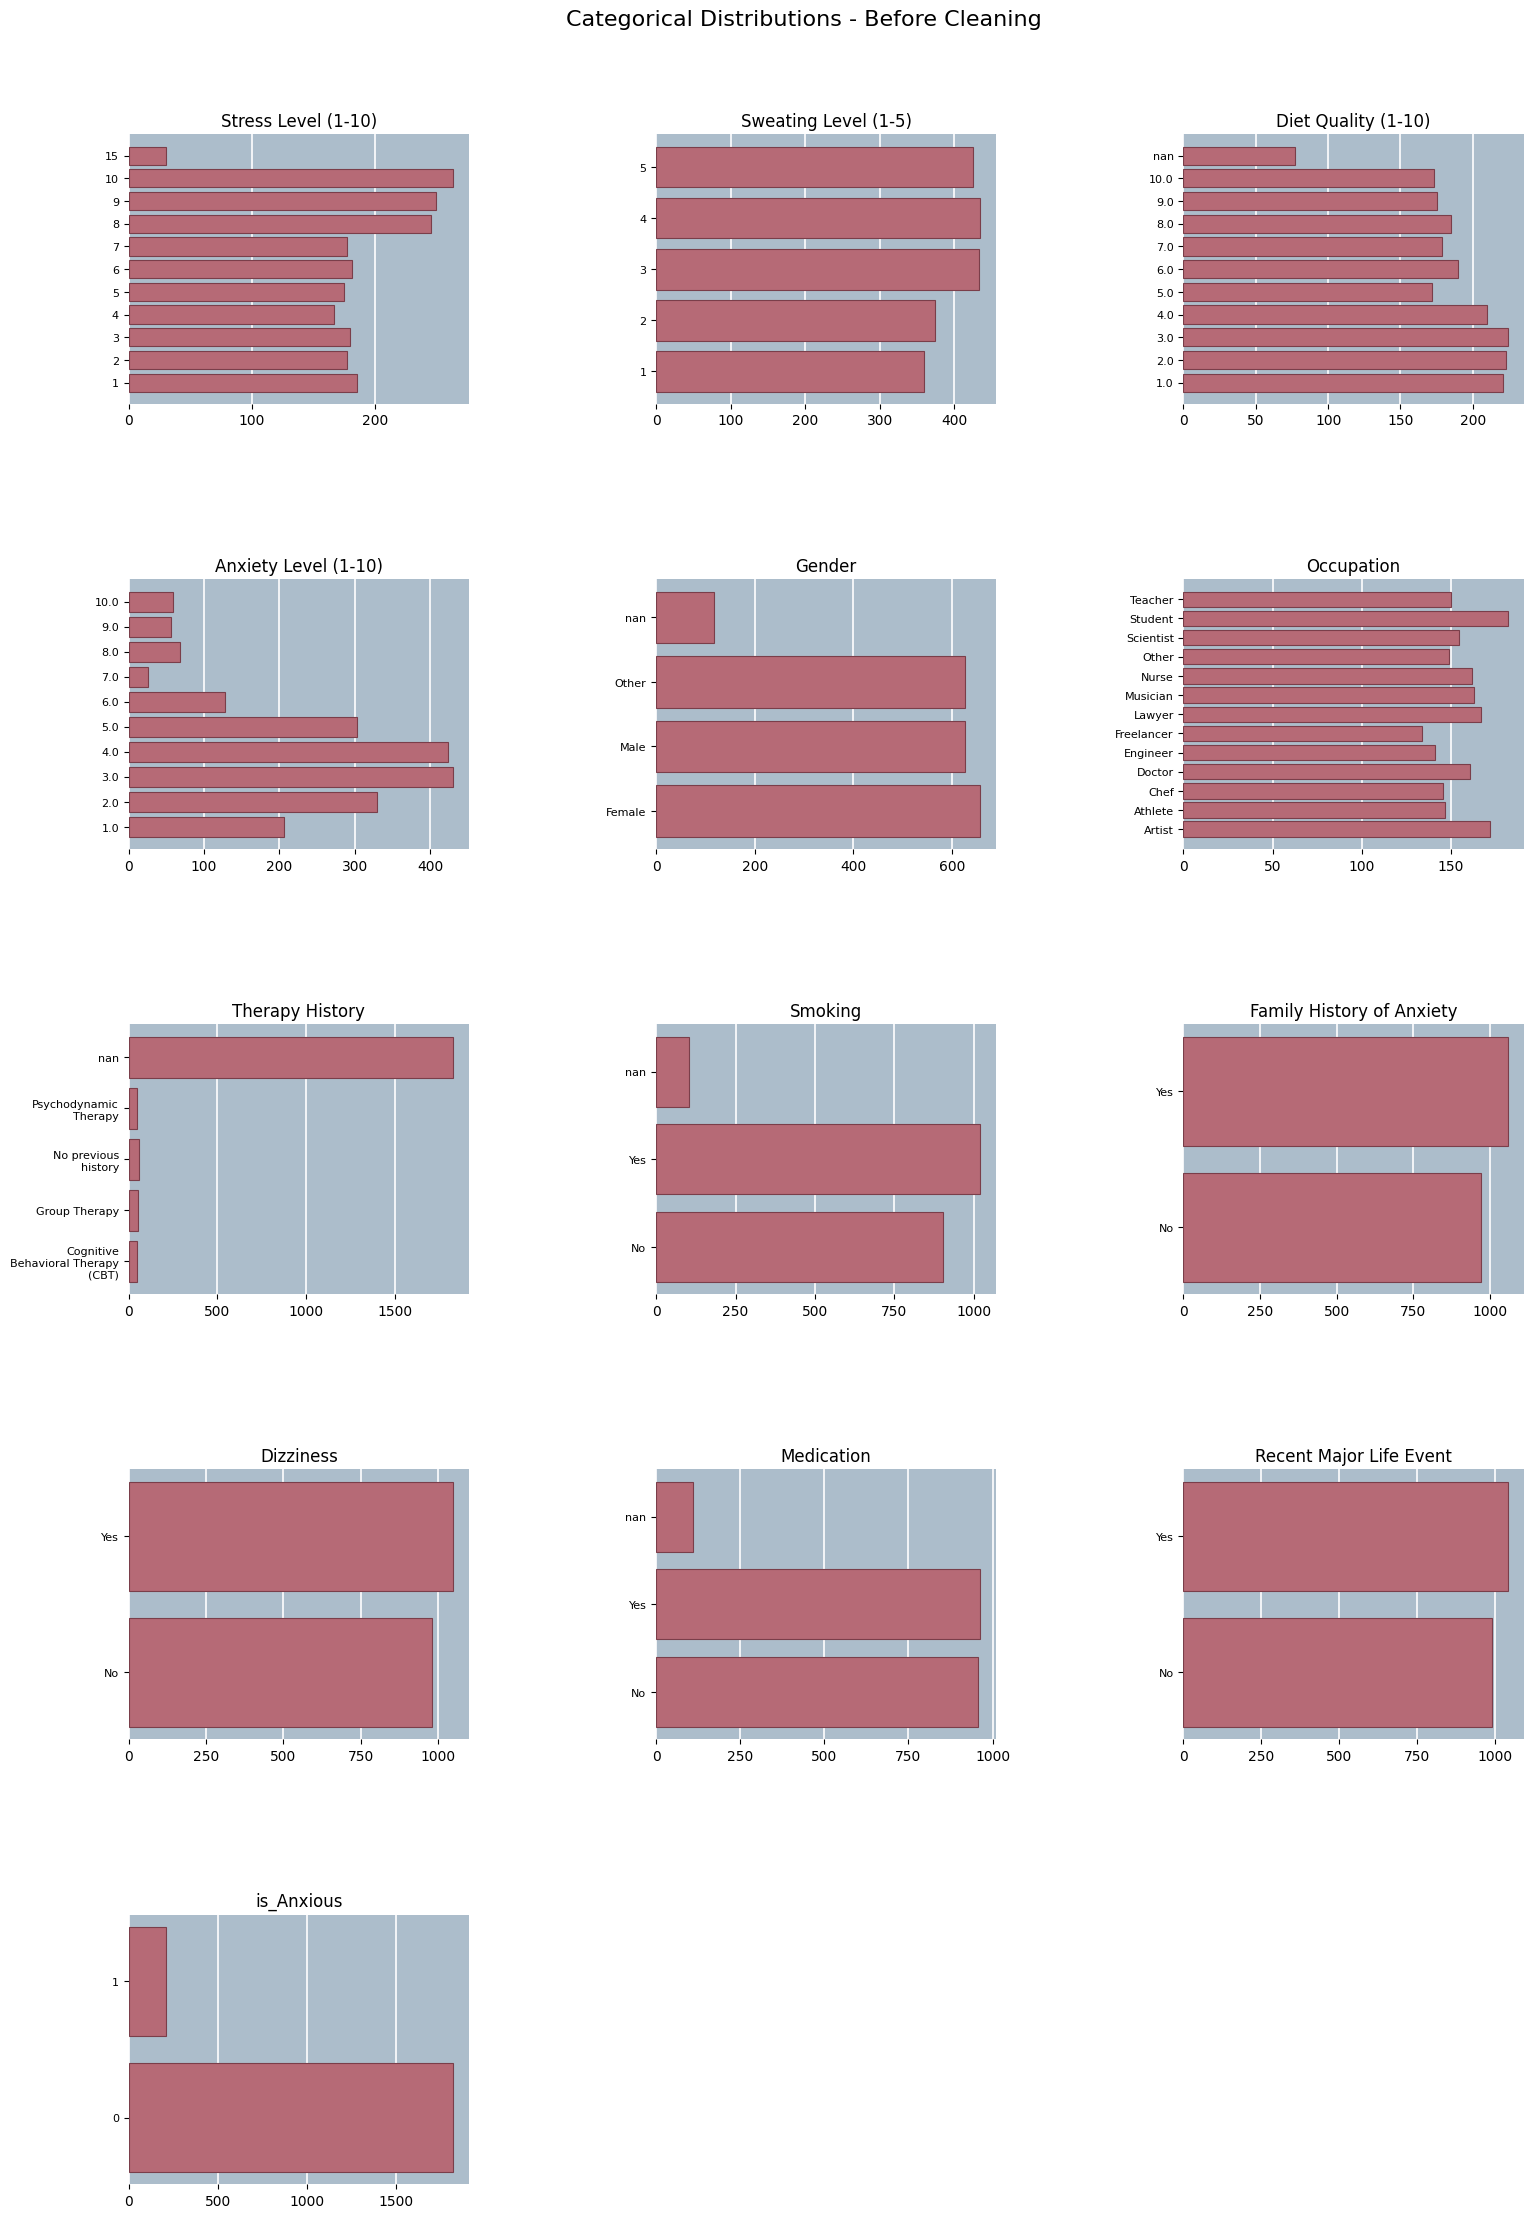

In [20]:
plot_bar_charts(dataframe, bar_columns)

# Are the numeric columns normal?

A Shapiro-Wilk test on each numeric column. Spoiler: none of them are. With around 2,000 rows Shapiro picks up even small departures from normality, but it's still a useful hint: medians and non-parametric tests are the safer choice from here on.

In [21]:
def check_normality(data, columns):

    for col in columns:

        values = data[col].dropna()

        stat, p = shapiro(values)

        if p > 0.05:
            print(col, ": Normal")
        else:
            print(col, ": Not Normal")

In [22]:
check_normality(dataframe, numeric_columns)

Age : Not Normal
Sleep Hours : Not Normal
Physical Activity (hrs/week) : Not Normal
Caffeine Intake (mg/day) : Not Normal
Alcohol Consumption (drinks/week) : Not Normal
Heart Rate (bpm) : Not Normal
Breathing Rate (breaths/min) : Not Normal
Therapy Sessions (per month) : Not Normal


# Impossible values

Some values simply can't be real: negative sleep or exercise, negative drinks per week, a stress score of 15 on a 1–10 scale. We count them first, then turn them into `NaN` and keep a `*_Invalid_Flag` column so we don't lose track of which values we touched.

In [23]:
def check_invalid(data, col, low, high=None):

    if high is None:
        invalid = data[col] < low
    else:
        invalid = (data[col] < low) | (data[col] > high)

    print(col, ":", invalid.sum())

In [24]:
invalid_rules = [
    ("Age", 1, None),
    ("Sleep Hours", 0, 24),
    ("Physical Activity (hrs/week)", 0, 168),
    ("Caffeine Intake (mg/day)", 0, None),
    ("Alcohol Consumption (drinks/week)", 0, None),
    ("Heart Rate (bpm)", 1, None),
    ("Breathing Rate (breaths/min)", 1, None),
    ("Therapy Sessions (per month)", 0, None),

    ("Stress Level (1-10)", 1, 10),
    ("Sweating Level (1-5)", 1, 5),
    ("Diet Quality (1-10)", 1, 10),
    ("Anxiety Level (1-10)", 1, 10)
]

In [25]:
for col, low, high in invalid_rules:
    check_invalid(dataframe, col, low, high)

Age : 0
Sleep Hours : 40
Physical Activity (hrs/week) : 40
Caffeine Intake (mg/day) : 0
Alcohol Consumption (drinks/week) : 40
Heart Rate (bpm) : 0
Breathing Rate (breaths/min) : 0
Therapy Sessions (per month) : 0
Stress Level (1-10) : 30
Sweating Level (1-5) : 0
Diet Quality (1-10) : 0
Anxiety Level (1-10) : 0


In [26]:
def fix_invalid(col, low, high):

    flag_col = col + "_Invalid_Flag"

    dataframe[flag_col] = 0

    if high is None:
        invalid = dataframe[col] < low
    else:
        invalid = (dataframe[col] < low) | (dataframe[col] > high)

    if invalid.any():
        dataframe.loc[invalid, flag_col] = 1
        dataframe.loc[invalid, col] = np.nan

In [27]:
fix_invalid("Sleep Hours", 0, 24)

fix_invalid("Physical Activity (hrs/week)", 0, 168)

fix_invalid("Alcohol Consumption (drinks/week)", 0, np.inf)

fix_invalid("Stress Level (1-10)", 1, 10)

# Capping outliers

For the numeric columns we use the classic IQR rule: anything more than 1.5 × IQR beyond the quartiles gets pulled back to that boundary. Rows that were capped are marked in a `*_Outlier_FG` column.

In [28]:
def cap_outliers(data, columns):

    for col in columns:

        data[col] = data[col].astype(float)

    for col in columns:

        q1 = data[col].quantile(0.25)
        q3 = data[col].quantile(0.75)

        IQR = q3 - q1

        lower = q1 - 1.5 * IQR
        upper = q3 + 1.5 * IQR

        outlier = (data[col] < lower) | (data[col] > upper)

        if outlier.any():

            flag_col = col + "_Outlier_FG"
            data[flag_col] = 0

            data.loc[outlier, flag_col] = 1

            data.loc[data[col] < lower, col] = lower
            data.loc[data[col] > upper, col] = upper

    return data

In [29]:
dataframe = cap_outliers(dataframe, numeric_columns)

# Flagging missing values

Before filling anything in, each column with gaps gets a `*_Missing_Flag` column. The values we turned into `NaN` ourselves (the invalid ones) are subtracted out, so this flag only marks values that were missing in the original file.

In [30]:
missing_columns = [
    col for col in dataframe.columns
    if dataframe[col].isnull().any() and "_FG" not in col
]

In [31]:
def add_missing_flags(data, columns):

    for col in columns:

        missing = data[col].isnull().astype(int)

        invalid_flag = col + "_Invalid_Flag"
        missing_flag = col + "_Missing_Flag"

        if invalid_flag in data.columns:
            data[missing_flag] = missing - data[invalid_flag]

        else:
            data[missing_flag] = missing

    return data

In [32]:
dataframe = add_missing_flags(dataframe, missing_columns)

In [33]:
for col in missing_columns:
    print(col, ":", dataframe[col + "_Missing_Flag"].sum())

Age : 62
Gender : 118
Sleep Hours : 36
Physical Activity (hrs/week) : 0
Caffeine Intake (mg/day) : 93
Alcohol Consumption (drinks/week) : 0
Smoking : 105
Stress Level (1-10) : 0
Medication : 109
Diet Quality (1-10) : 77
Therapy History : 1826


# Normality, round two

The same test after fixing the invalid values and capping outliers. Still not normal, so the median is the way to go for filling gaps.

In [34]:
check_normality(dataframe, numeric_columns)

Age : Not Normal
Sleep Hours : Not Normal
Physical Activity (hrs/week) : Not Normal
Caffeine Intake (mg/day) : Not Normal
Alcohol Consumption (drinks/week) : Not Normal
Heart Rate (bpm) : Not Normal
Breathing Rate (breaths/min) : Not Normal
Therapy Sessions (per month) : Not Normal


# Filling missing values

Numeric and ordinal columns get the median. The three categorical columns with gaps (`Gender`, `Smoking`, `Medication`) get their most common value.

In [35]:
def fill_numeric_missing(data, columns):

    for col in columns:
        median_value = data[col].median()
        data[col] = data[col].fillna(median_value)

    return data

In [36]:
dataframe = fill_numeric_missing(dataframe, numeric_columns)

In [37]:
def fill_ordinal_missing(data, columns):

    for col in columns:

        if data[col].isnull().sum() > 0:
            median_value = data[col].median()
            data[col] = data[col].fillna(median_value)

    return data

In [38]:
dataframe = fill_ordinal_missing(dataframe, ordinal_columns)

In [39]:
categorical_missing_columns = [
    "Gender",
    "Smoking",
    "Medication"
]

In [40]:
def fill_categorical_missing(data, columns):

    for col in columns:

        if data[col].isnull().sum() > 0:
            mode_value = data[col].mode()[0]
            data[col] = data[col].fillna(mode_value)

    return data

In [41]:
dataframe = fill_categorical_missing(dataframe, categorical_missing_columns)

# Numeric columns after cleaning

The same charts as before, now on the cleaned data. The impossible values and extreme outliers are gone.

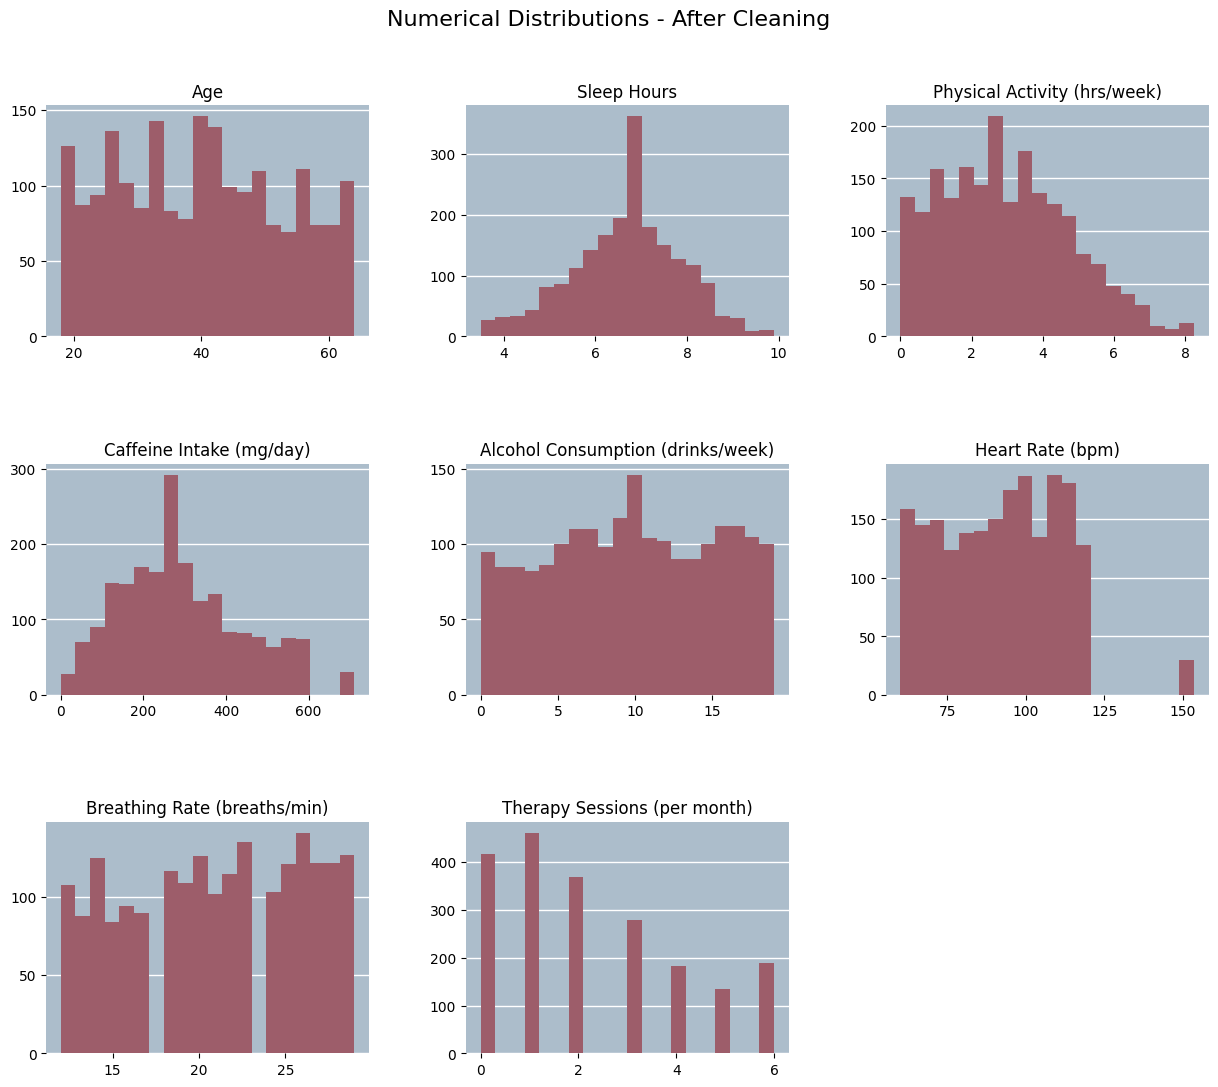

In [42]:
plot_histograms(dataframe, numeric_columns, title="Numerical Distributions - After Cleaning")

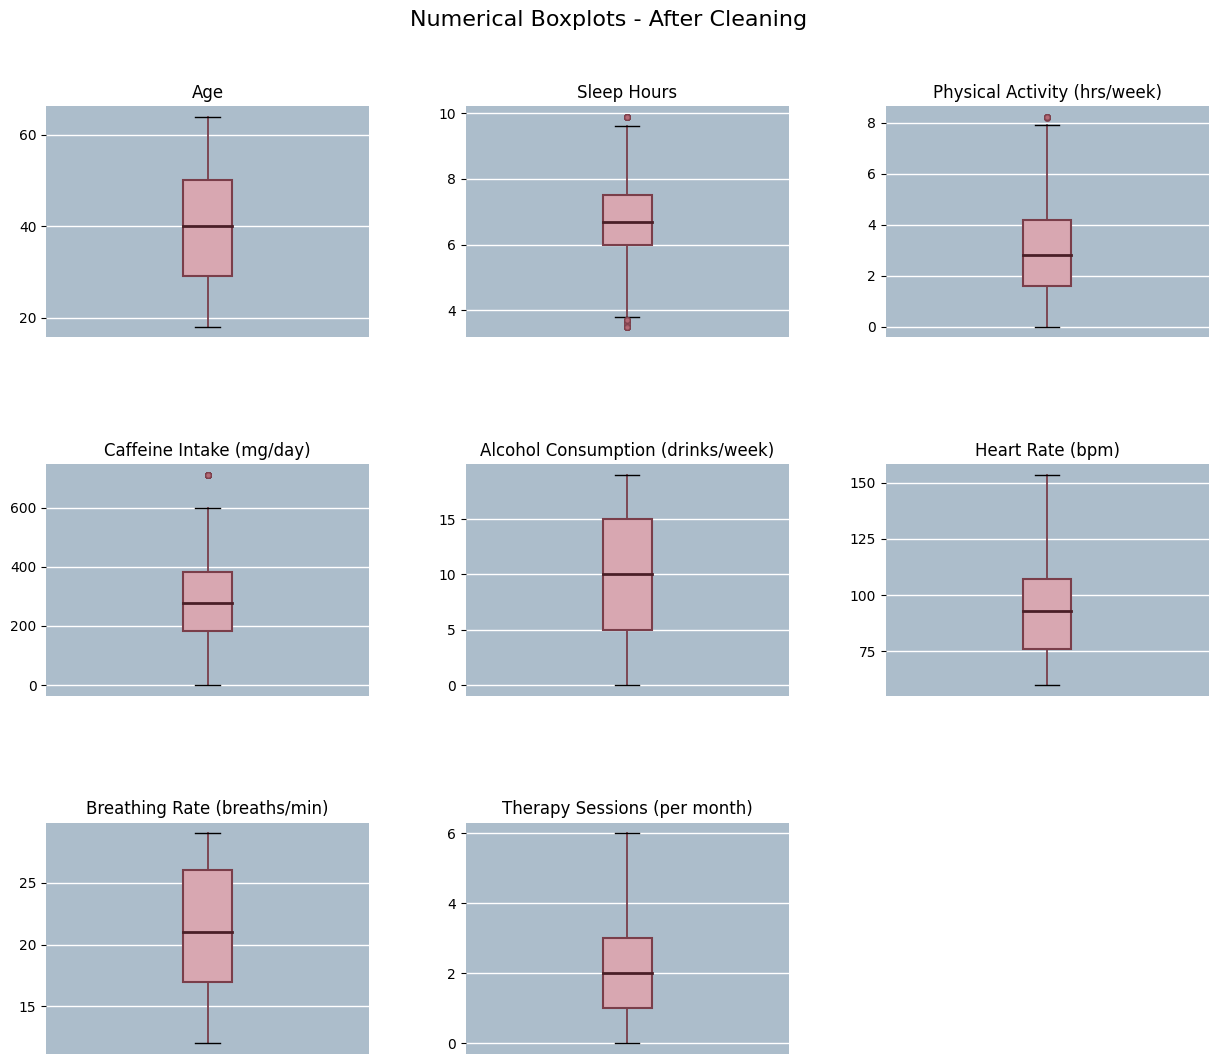

In [43]:
plot_boxplots(dataframe, numeric_columns, title="Numerical Boxplots - After Cleaning")

# Regrouping categories

Thirteen occupations means a lot of small groups, so we fold them into four broader buckets based on the kind of pressure each job tends to come with. `Therapy History` is collapsed into a simple Yes / No.

Heads up: `Therapy History` is about 90% empty, so anything based on it only uses a small slice of the data.

In [44]:
critical = ["Doctor", "Lawyer", "Nurse", "Chef"]
structured = ["Engineer", "Scientist", "Teacher"]
creative = ["Freelancer", "Artist", "Musician", "Athlete"]
others = ["Student", "Other"]

conditions = [
    dataframe["Occupation"].isin(critical),
    dataframe["Occupation"].isin(structured),
    dataframe["Occupation"].isin(creative),
    dataframe["Occupation"].isin(others)
]

choices = ["Critical", "Structured", "Creative", "Others"]

dataframe["Job_Category"] = np.select(conditions, choices, default="Others")

In [45]:
dataframe["Therapy History Reclassified"] = dataframe["Therapy History"].replace({
    "Cognitive Behavioral Therapy": "Yes",
    "Group Therapy": "Yes",
    "Psychodynamic Therapy": "Yes",
    "No previous history": "No"
})

# Binning

Some numbers are easier to reason about as ranges, especially when there are well-known reference points: 7–9 hours of sleep, 400 mg of caffeine a day, a resting heart rate of 100 bpm. So we cut those columns into labelled groups.

In [46]:
def apply_binnings(df):

    data = df.copy()

    data["Sleep_Category"] = pd.cut(
        data["Sleep Hours"],
        bins=[
            data["Sleep Hours"].min(),
            6.5,
            9.0,
            data["Sleep Hours"].max() + 0.01
        ],
        labels=["Short_Sleep", "Optimal_Sleep", "Long_Sleep"],
        include_lowest=True,
        right=False
    )

    data["Caffeine_Category"] = pd.cut(
        data["Caffeine Intake (mg/day)"],
        bins=[
            data["Caffeine Intake (mg/day)"].min(),
            100,
            400,
            data["Caffeine Intake (mg/day)"].max() 
        ],
        labels=["Low", "Moderate", "High_Risk"],
        include_lowest=True
    )

    data["Activity_Category"] = pd.cut(
        data["Physical Activity (hrs/week)"],
        bins=[
            data["Physical Activity (hrs/week)"].min(),
            1.499,
            2.5,
            data["Physical Activity (hrs/week)"].max() + 0.01
        ],
        labels=["Sedentary", "Active", "Highly_Active"],
        include_lowest=True,
        right=False
    )

    data["Alcohol_Category"] = pd.cut(
        data["Alcohol Consumption (drinks/week)"],
        bins=[
            data["Alcohol Consumption (drinks/week)"].min(),
            6,
            12,
            data["Alcohol Consumption (drinks/week)"].max()
        ],
        labels=["Low", "Moderate", "Heavy_Risk"],
        include_lowest=True
    )

    data["Heart_Rate_Category"] = pd.cut(
        data["Heart Rate (bpm)"],
        bins=[
            data["Heart Rate (bpm)"].min(),
            100,
            data["Heart Rate (bpm)"].max()
        ],
        labels=["Normal", "Tachycardia"],
        include_lowest=True
    )

    data["Breathing_Category"] = pd.cut(
        data["Breathing Rate (breaths/min)"],
        bins=[
            data["Breathing Rate (breaths/min)"].min(),
            20,
            data["Breathing Rate (breaths/min)"].max()
        ],
        labels=["Normal_Breathing", "Tachypnea"],
        include_lowest=True
    )

    data["Stress_Category"] = pd.cut(
        data["Stress Level (1-10)"],
        bins=[
            data["Stress Level (1-10)"].min(),
            3,
            7,
            data["Stress Level (1-10)"].max()
        ],
        labels=["Low", "Moderate", "High"],
        include_lowest=True
    )

    data["Therapy_Engagement"] = pd.cut(
        data["Therapy Sessions (per month)"],
        bins=[
            data["Therapy Sessions (per month)"].min(),
            1,
            4,
            data["Therapy Sessions (per month)"].max() + 0.01
        ],
        labels=["No_Therapy", "Short_Term", "Ongoing_Therapy"],
        include_lowest=True,
        right=False
    )

    data["Age_Group"] = pd.cut(
        data["Age"],
        bins=[17, 29, 49, 65],
        labels=["Young Adult", "Adult", "Middle-Aged"],
        include_lowest=True
    )

    data["Age_Group2"] = pd.cut(
        data["Age"],
        bins=[17, 29, 39, 49, 59, 69],
        labels=["18-29", "30-39", "40-49", "50-59", "60-69"],
        include_lowest=True
    )

    return data

In [47]:
dataframe = apply_binnings(dataframe)

In [48]:
bin_columns = [
    "Sleep_Category",
    "Caffeine_Category",
    "Activity_Category",
    "Alcohol_Category",
    "Heart_Rate_Category",
    "Breathing_Category",
    "Stress_Category",
    "Therapy_Engagement",
    "Age_Group",
    "Age_Group2"
]

dataframe[bin_columns].head()

,Sleep_Category,Caffeine_Category,Activity_Category,Alcohol_Category,Heart_Rate_Category,Breathing_Category,Stress_Category,Therapy_Engagement,Age_Group,Age_Group2
0,Optimal_Sleep,Low,Active,Low,Normal,Tachypnea,Moderate,No_Therapy,Middle-Aged,50-59
1,Short_Sleep,Moderate,Highly_Active,Moderate,Normal,Normal_Breathing,Low,Short_Term,Adult,40-49
2,Short_Sleep,High_Risk,Active,Heavy_Risk,Tachycardia,Tachypnea,High,Ongoing_Therapy,Adult,40-49
3,Optimal_Sleep,Moderate,Sedentary,Low,Tachycardia,Normal_Breathing,High,Short_Term,Adult,40-49
4,Optimal_Sleep,Low,Highly_Active,Heavy_Risk,Tachycardia,Normal_Breathing,Moderate,No_Therapy,Young Adult,18-29


# Feature engineering

Three new features:

- `Lifestyle_Health_Score`: the average of scaled physical activity, diet quality and (flipped) alcohol use. Higher means a healthier lifestyle.
- `Physiological_Arousal`: heart rate × breathing rate, scaled to 0–1. A rough measure of how "revved up" the body is.
- `Caffeine_Sleep_Ratio`: milligrams of caffeine per hour of sleep.

In [49]:
def scale_feature(series):

    scaled = (
        (series - series.min()) /
        (series.max() - series.min())
    )

    return scaled

In [50]:
activity_scaled = scale_feature(
    dataframe["Physical Activity (hrs/week)"]
)

diet_scaled = scale_feature(
    dataframe["Diet Quality (1-10)"]
)

alcohol_scaled = scale_feature(
    dataframe["Alcohol Consumption (drinks/week)"]
)

dataframe["Lifestyle_Health_Score"] = (
    (activity_scaled + diet_scaled +(1- alcohol_scaled))
) / 3 

dataframe["Lifestyle_Health_Score"]

0       0.342584
1       0.358533
2       0.275598
3       0.406734
4       0.337586
          ...   
2025    0.171753
2026    0.316676
2027    0.341450
2028    0.276413
2029    0.711005
Name: Lifestyle_Health_Score, Length: 2029, dtype: float64

In [51]:
raw_arousal = (
    dataframe["Heart Rate (bpm)"] *
    dataframe["Breathing Rate (breaths/min)"]
)

dataframe["Physiological_Arousal"] = scale_feature(raw_arousal)

dataframe["Physiological_Arousal"]

0       0.262437
1       0.170486
2       0.448016
3       0.317496
4       0.430688
          ...   
2025    0.271381
2026    0.146730
2027    0.358301
2028    0.274176
2029    0.234768
Name: Physiological_Arousal, Length: 2029, dtype: float64

In [52]:
sleep_hours = dataframe["Sleep Hours"].replace(0, 0.1)

dataframe["Caffeine_Sleep_Ratio"] = (
    dataframe["Caffeine Intake (mg/day)"] /
    sleep_hours
).round(2)

In [53]:
new_features = [
    "Lifestyle_Health_Score",
    "Physiological_Arousal",
    "Caffeine_Sleep_Ratio"
]

dataframe[new_features].head()

,Lifestyle_Health_Score,Physiological_Arousal,Caffeine_Sleep_Ratio
0,0.342584,0.262437,5.71
1,0.358533,0.170486,30.59
2,0.275598,0.448016,111.76
3,0.406734,0.317496,16.97
4,0.337586,0.430688,9.55


# Cleaning done, on to the analysis

The data is in shape now. From here on we look at how each variable relates to `is_Anxious`: charts first, then statistical tests to check whether what we see is more than noise.

## Column groups for the analysis

The lists are updated to include the new features and bins. `is_Anxious` is the target.

In [54]:
numerical_columns = [
    "Age",
    "Sleep Hours",
    "Physical Activity (hrs/week)",
    "Caffeine Intake (mg/day)",
    "Alcohol Consumption (drinks/week)",
    "Heart Rate (bpm)",
    "Breathing Rate (breaths/min)",
    "Therapy Sessions (per month)",
    "Lifestyle_Health_Score",
    "Physiological_Arousal",
    "Caffeine_Sleep_Ratio"]


categorical_columns = [
    "Gender",
    "Occupation",
    "Smoking",
    "Family History of Anxiety",
    "Dizziness",
    "Medication",
    "Recent Major Life Event",
    "Therapy History",
    "Job_Category",
    "Therapy History Reclassified",
    "Sleep_Category",
    "Caffeine_Category",
    "Activity_Category",
    "Alcohol_Category",
    "Heart_Rate_Category",
    "Breathing_Category",
    "Stress_Category",
    "Therapy_Engagement",
    "Age_Group",
    "Age_Group2",
]
ordinal_columns = [
    "Stress Level (1-10)",
    "Sweating Level (1-5)",
    "Diet Quality (1-10)",
    "Anxiety Level (1-10)"]
target = 'is_Anxious'

## Contingency tables

A small helper that cross-tabulates a categorical column against the target, in both wide and long format. The long one is handy for Plotly.

In [55]:


def crosstab_table(data, col):
    ct_wide =  pd.crosstab(data[col] , data[target]).sort_index()
    
    ct_wide_reset= ct_wide.reset_index()
    ct_long = ct_wide_reset.melt( id_vars=col , var_name=target , value_name="Count")
    return ct_wide , ct_long


# Categorical variables vs. anxiety

This part has two steps.

**First, the charts.** For each categorical column we plot four things: how many people are in each group (bar chart and treemap), how those groups split by `is_Anxious`, and the share of anxious people inside each group. That last one is usually the most telling.

**Then, the test.** Charts can fool you, so every column also gets a Chi-Square test of independence. The null hypothesis is that the anxiety rate is the same in every group. If `p < 0.05`, we reject it.

A small p-value only says the difference is probably real, not that it's big. With 2,000 rows even tiny differences come out significant. That's why we also compute **Cramér's V**, which goes from 0 (no association) to 1 (perfect association):

V = √(χ² / (n × min(r − 1, c − 1)))

where χ² is the test statistic, n is the number of people, and r and c are the number of rows and columns in the contingency table.

In [56]:

def categorical_plots(data, col, target):
    data[target] = data[target].astype(str)
    color_map_target = {
        "0": "#82A3D0",  
        "1": "#B4535A",
    }
    ct_wide, ct_long = crosstab_table(data, col)

    totals = ct_wide.sum(axis=1).reset_index()
    totals.columns = [col, "Count"]

    rate = (ct_wide.div(ct_wide.sum(axis=1), axis=0) * 100).round(2)

    d = data.copy()
    d[col] = d[col].astype(str)
    counts = d[col].value_counts().reset_index()
    counts.columns = [col, "Count"]

    
    fig1 = px.bar(totals, x=col, y="Count" , color_discrete_sequence=["#385986"])
    fig2 = px.treemap(counts, path=[col], values="Count",  color_continuous_scale='RdBu')
    fig3 = px.bar(ct_long, x=col, y="Count", color=target , color_discrete_map=color_map_target)

    
    fig = subplots.make_subplots(
        rows=2, cols=2,
        subplot_titles=(
            f"Total observation by {col}",
            f"Frequency of {col}",
            f"{col} by {target} status",
            f"{target} rate within {col} (%)",
        ),
        horizontal_spacing=0.12, vertical_spacing=0.15,
        specs=[[{"type": "xy"}, {"type": "domain"}],
               [{"type": "xy"}, {"type": "xy"}]],
    )

    
    for t in fig1.data:
        t.showlegend = False
        fig.add_trace(t, row=1, col=1)

    
    for t in fig2.data:
        fig.add_trace(t, row=1, col=2)

    
    for i, t in enumerate(fig3.data):
        t.showlegend = True
        fig.add_trace(t, row=2, col=1)

    
    x_cats = rate.index.tolist()
    targets_order = rate.columns.tolist()
    color_map = {}
    for t in fig3.data:
        color_map[t.name] = t.marker.color

    cumulative = np.zeros(len(x_cats))
    for tname in targets_order:
        vals = rate[tname].fillna(0).values
        fig.add_trace(
            go.Bar(
                x=x_cats,
                y=vals,
                name=str(tname),
                legendgroup=str(tname),
                showlegend=False,
                marker_color=color_map.get(str(tname), None),
                marker_line=dict(color="white", width=0.5),
                base=cumulative.copy(),
                offsetgroup="stack_rate",    
            ),
            row=2, col=2,
        )
        cumulative = cumulative + vals

    fig.update_layout(
        template="plotly_white",
        paper_bgcolor="#F5F7FA",
        plot_bgcolor="#FFFFFF",
        title = 'Categorical Variable Analysis', title_x = 0.5,
        font=dict(
            family="Arial",
            color="#334155",
            size=12
        ),
        treemapcolorway = [
        "#870D1C",
        "#A64B55",
        "#C77C85",
        "#64748B",
        "#94A3B8",
        "#CBD5E1"],

        height=600, width=1200,
        barmode="group",                    
        legend_title=target,
        margin=dict(t=80, l=40, r=40, b=40),
        

        legend=dict(
            orientation="h",  x=0.5, y=0.46,
            xanchor="center", yanchor="bottom"
        )

    )


    fig.update_yaxes(range=[0, 100], row=2, col=2, ticksuffix="%")

    for t in fig.data:
        if isinstance(t, go.Bar):
            t.text = t.y
            t.textposition = "inside"
            t.texttemplate = "%{text:.0f}"

    def shorten(label, max_len=15):
        if len(label) <= max_len:
            return label
        return label[:max_len - 1] + "…"

    vals = ct_long[col].unique()
    short = {v: shorten(v) for v in vals}

    for i in (1,2):
        fig.update_xaxes(
            tickvals=list(short.keys()),
            ticktext=list(short.values()),
            row = i
        )
    save_figure(fig, f"categorical_{col}")
    fig.show()


for i in categorical_columns:
    categorical_plots(dataframe , i , target)

## Chi-Square test

The test function, run on one column as an example.

In [57]:
def categorical_chi_square_test(data, col, target, alpha=0.05):

    ct = pd.crosstab(data[col], data[target])
    chi2, p_value, dof, expected = chi2_contingency(ct)

    n = ct.to_numpy().sum()
    r, k = ct.shape

    cramers_v = np.sqrt((chi2 / n) / min(r - 1, k - 1))

    h0 = f"The anxiety rate is the same across categories of {col}."
    h1 = f"The anxiety rate is not the same across categories of {col}."

    print(f"Chi-Square Test: {col} vs {target}")

    print("\nHypotheses:")
    print(f"H0: {h0}")
    print(f"H1: {h1}")

    print("\nTest Results:")
    print(f"Chi-Square Statistic: {chi2:.3f}")
    print(f"Degrees of Freedom: {dof}")
    print(f"p-value: {p_value:.4f}")
    print(f"Cramer's V: {cramers_v:.3f}")

    print("\nConclusion:")

    if p_value < alpha:
        print(
            f"Since the p-value ({p_value}) is less than "
            f"the significance level ({alpha}), we reject H0."
        )
        print(
            f"There is statistically significant evidence that "
            f"the anxiety rate differs across categories of {col}."
        )
    else:
        print(
            f"Since the p-value ({p_value}) is greater than or equal to "
            f"the significance level ({alpha}), we fail to reject H0."
        )
        print(
            f"There is not enough statistical evidence to conclude that "
            f"the anxiety rate differs across categories of {col}."
        )

    if cramers_v < 0.10:
        strength = "Very Weak"
    elif cramers_v < 0.30:
        strength = "Weak"
    elif cramers_v < 0.50:
        strength = "Moderate"
    else:
        strength = "Strong"

    print(f"Association Strength: {strength}")

    return {
        "variable": col,
        "target": target,
        "chi2": chi2,
        "p_value": p_value,
        "degrees_of_freedom": dof,
        "cramers_v": cramers_v,
        "association_strength": strength,
        "reject_h0": p_value < alpha
    }
categorical_chi_square_test(dataframe , categorical_columns[-3] , target)

Chi-Square Test: Therapy_Engagement vs is_Anxious

Hypotheses:
H0: The anxiety rate is the same across categories of Therapy_Engagement.
H1: The anxiety rate is not the same across categories of Therapy_Engagement.

Test Results:
Chi-Square Statistic: 583.853
Degrees of Freedom: 2
p-value: 0.0000
Cramer's V: 0.536

Conclusion:
Since the p-value (1.6515864560729264e-127) is less than the significance level (0.05), we reject H0.
There is statistically significant evidence that the anxiety rate differs across categories of Therapy_Engagement.
Association Strength: Strong


{'variable': 'Therapy_Engagement',
 'target': 'is_Anxious',
 'chi2': 583.8531409914726,
 'p_value': 1.6515864560729264e-127,
 'degrees_of_freedom': 2,
 'cramers_v': 0.5364271949953165,
 'association_strength': 'Strong',
 'reject_h0': True}

## All categorical columns in one table

Running the test on every categorical column and collecting the results in one table, sorted by p-value, makes it easy to see what matters and what doesn't.

In [58]:
results = []
for col in categorical_columns:
    result = categorical_chi_square_test(dataframe,col, target)

    results.append({
        "Variable": col,   "P-Value": result["p_value"], "Cramer's V": result["cramers_v"],
        "Interpretation": (
            "Associated with Anxiety"
            if result["reject_h0"]
            else "Not significantly associated with Anxiety"),
        "Association Strength": result["association_strength"]})

categorical_bivariate_dataframe = pd.DataFrame(results)

categorical_bivariate_dataframe = (
    categorical_bivariate_dataframe.sort_values(by="P-Value", ascending=True).reset_index(drop=True)
)

categorical_bivariate_dataframe

Chi-Square Test: Gender vs is_Anxious

Hypotheses:
H0: The anxiety rate is the same across categories of Gender.
H1: The anxiety rate is not the same across categories of Gender.

Test Results:
Chi-Square Statistic: 1.601
Degrees of Freedom: 2
p-value: 0.4491
Cramer's V: 0.028

Conclusion:
Since the p-value (0.4490852331656958) is greater than or equal to the significance level (0.05), we fail to reject H0.
There is not enough statistical evidence to conclude that the anxiety rate differs across categories of Gender.
Association Strength: Very Weak
Chi-Square Test: Occupation vs is_Anxious

Hypotheses:
H0: The anxiety rate is the same across categories of Occupation.
H1: The anxiety rate is not the same across categories of Occupation.

Test Results:
Chi-Square Statistic: 8.301
Degrees of Freedom: 12
p-value: 0.7612
Cramer's V: 0.064

Conclusion:
Since the p-value (0.7611662971803334) is greater than or equal to the significance level (0.05), we fail to reject H0.
There is not enough s

,Variable,P-Value,Cramer's V,Interpretation,Association Strength
0,Therapy_Engagement,1.651586e-127,0.536427,Associated with Anxiety,Strong
1,Stress_Category,2.061315e-79,0.422601,Associated with Anxiety,Moderate
2,Sleep_Category,7.348783e-54,0.347270,Associated with Anxiety,Moderate
3,Activity_Category,6.477373e-49,0.330715,Associated with Anxiety,Moderate
4,Caffeine_Category,1.710366e-41,0.304184,Associated with Anxiety,Moderate
5,Family History of Anxiety,3.984361e-21,0.209416,Associated with Anxiety,Weak
6,Breathing_Category,8.740240e-19,0.196476,Associated with Anxiety,Weak
7,Heart_Rate_Category,1.501146e-12,0.157053,Associated with Anxiety,Weak
8,Age_Group,3.264770e-12,0.161462,Associated with Anxiety,Weak
9,Age_Group2,6.719515e-11,0.162371,Associated with Anxiety,Weak


## A closer look at the strongest ones

For the columns with a moderate or strong association, let's spell out the actual numbers: how many people are in each group and how many of them are anxious.

One thing to keep in mind with `Therapy_Engagement`: people most likely go to therapy *because* they're anxious, not the other way around. So this is an association and says nothing about therapy causing anxiety.

In [59]:
selected_variables = categorical_bivariate_dataframe.loc[ categorical_bivariate_dataframe["Association Strength"].isin(["Moderate", "Strong"]),"Variable"].tolist()

for col in selected_variables:
    temp = (
        dataframe.assign(
            target_numeric=pd.to_numeric(dataframe[target], errors="coerce"))
        .groupby(col)["target_numeric"]
        .agg(Sample_Size="count",Depression_Count="sum",Depression_Rate="mean")
        .reset_index()
    )

    temp["Depression_Rate"] = (temp["Depression_Rate"] * 100).round(2)
    print('.' * 10) 
    print(f"Analysis of {col} \n")

    for _ , row in temp.iterrows():
        print(
            f"• {row[col]}: "
            f"{row['Depression_Rate']:.2f}% Anxious "
            f"({int(row['Depression_Count'])} out of "
            f"{int(row['Sample_Size'])} participants)"
        )

..........
Analysis of Therapy_Engagement 

• No_Therapy: 0.00% Anxious (0 out of 417 participants)
• Short_Term: 1.26% Anxious (14 out of 1107 participants)
• Ongoing_Therapy: 38.61% Anxious (195 out of 505 participants)
..........
Analysis of Stress_Category 

• Low: 0.00% Anxious (0 out of 542 participants)
• Moderate: 0.68% Anxious (5 out of 730 participants)
• High: 26.95% Anxious (204 out of 757 participants)
..........
Analysis of Sleep_Category 

• Short_Sleep: 23.60% Anxious (185 out of 784 participants)
• Optimal_Sleep: 2.01% Anxious (24 out of 1194 participants)
• Long_Sleep: 0.00% Anxious (0 out of 51 participants)
..........
Analysis of Activity_Category 

• Sedentary: 26.32% Anxious (125 out of 475 participants)
• Active: 15.14% Anxious (56 out of 370 participants)
• Highly_Active: 2.36% Anxious (28 out of 1184 participants)
..........
Analysis of Caffeine_Category 

• Low: 0.61% Anxious (1 out of 164 participants)
• Moderate: 5.95% Anxious (84 out of 1411 participants)
•

# Two categorical variables at once

Here we check whether combining two categorical columns shows something neither one shows on its own. With 20 categorical columns there are far too many pairs to chart, so we tried out a set of pairs and kept the ones that looked interesting. Because the pairs were picked that way, treat this section as exploratory.

For each pair there's a heatmap of the anxiety rate in every combination of groups, and a grouped bar chart of the same thing.

In [60]:
def cat_trivariate(data, col1, col2, target):
    data = data.copy()
    data[target] = (data[target].astype(str) == "1").astype(int)
    def cat_cat_target_heatmap(data, col1, col2, target):
        pivot = data.pivot_table(index=col2, columns=col1, values=target, aggfunc="mean") * 100

        fig = px.imshow(pivot, aspect="auto",
            color_continuous_scale=[
                                    "#E2E8F0",
                                    "#CBD5E1",
                                    "#A64B55",
                                    "#870D1C"
                                    ],
            labels=dict(x=col1, y=col2, color=f"% {target}"), text_auto=".1f",)

        fig.update_layout(template="plotly_white", title_x=0.5,)
        return fig

    def cat_cat_bar(data, col1, col2, target):
        ct = pd.crosstab([data[col1], data[col2]], data[target], normalize="index") * 100
        ct = ct.reset_index()
        fig = px.bar(ct, x=col1, y=ct.columns[-1],
                    color=col2, barmode="group", color_discrete_sequence=px.colors.qualitative.Antique)
        
        fig.update_layout(template="plotly_white", title_x=0.5)
        return fig

    fig = subplots.make_subplots(
        rows=1, cols=2,
        horizontal_spacing=0.08)

    fig1 = cat_cat_target_heatmap(data, col1, col2, target)
    fig2 = cat_cat_bar(data, col1, col2, target)

    for trace in fig1.data:
        fig.add_trace(trace, row=1, col=1)

    for i, trace in enumerate(fig2.data):
        fig.add_trace(trace, row=1, col=2)




    fig.update_layout(
        height=400, width=1250,
        barmode="group",
        plot_bgcolor="#FFFFFF",
        paper_bgcolor="#F5F7FA",
        font=dict(color="#333"),
        
        title=dict(
        text=f"{target} Rate by {col1} and {col2}",
        x=0.5,
        xanchor="center",
        y=0.95,
        yanchor="top",
        font=dict(size=20, color="#222")),
        
        coloraxis=dict(
            colorscale=[
                [0.00, "#E2E8F0"],
                [0.15, "#CBD5E1"],
                [0.30, "#AAB5C3"],
                [0.45, "#94A3B8"],
                [0.60, "#64748B"],
                [0.75, "#B66A76"],
                [0.88, "#A64B55"],
                [1.00, "#870D1C"],
            ]),

        coloraxis_colorbar=dict(
            title=dict(text=f"% {target}", font=dict(size=10, color="#333"), side="bottom"),
            tickfont=dict(size=8), 
            x=-0.05, xanchor="right",
            y=0.5, yanchor="middle",
            len=0.8),
            
        legend=dict(
            x=1.02,xanchor="left",y=0.5, yanchor="middle",
            title=col2,
            bgcolor="#F6F9FE",bordercolor="#DDD", borderwidth=1,),
    )


    fig.update_xaxes(title_text=col1, tickfont=dict(size=10), title_font=dict(size=12),
        row=1,col=1)

    fig.update_yaxes(
        title_text=col2, tickfont=dict(size=10),
        title_font=dict(size=11), title_standoff=3, row=1,col=1)

    fig.update_xaxes(
        title_text=col1, tickfont=dict(size=10),
        title_font=dict(size=12), row=1, col=2)

    fig.update_yaxes(
        title_text=f"% {target}",tickfont=dict(size=10),
        title_font=dict(size=12),
        row=1,col=2)
    save_figure(fig, f"trivariate_{col1}_{col2}")
    fig.show()




priority_pairs = [
    ("Job_Category", "Caffeine_Category"),
    ("Therapy_Engagement", "Age_Group2"),
    ("Therapy_Engagement", "Recent Major Life Event"),
    ("Sleep_Category", "Age_Group2"),
    ("Therapy_Engagement", "Sleep_Category"),
    ("Recent Major Life Event", "Age_Group2"),
    ("Therapy_Engagement", "Activity_Category"),
    ("Therapy_Engagement", "Alcohol_Category"),
    ("Job_Category", "Sleep_Category")]

for col1, col2 in priority_pairs:
    cat_trivariate(
        dataframe,
        col1,
        col2,
        target
    )

## Testing the pairs

For each pair we fit logistic regressions (Binomial GLM) and compare them with likelihood ratio tests. That answers three questions:

- Does variable 1 still matter once variable 2 is in the model?
- Does variable 2 still matter once variable 1 is in the model?
- Is there an **interaction**, meaning the effect of one variable depends on the level of the other?

Since we're running several tests, the interaction p-values are also adjusted with Benjamini-Hochberg (`Interaction P-Adj`).

**Caveat:** some combinations contain zero anxious people (nobody in `No_Therapy` is anxious, for example). Logistic regression can't handle that well. It's called perfect separation, and it's what the overflow and singular matrix warnings are about. Interaction p-values for those pairs aren't reliable, and a p-value of exactly 1.0 is a giveaway.

In [61]:
def categorical_trivariate_test(data, col1, col2, target, alpha=0.05):

    data = data[[col1, col2, target]].copy()
    data[target] = pd.to_numeric(data[target], errors="coerce")
    data = data.dropna()

    f1 = f"{target} ~ C(Q('{col1}'))"
    f2 = f"{target} ~ C(Q('{col2}'))"
    f12 = f"{target} ~ C(Q('{col1}')) + C(Q('{col2}'))"
    f3 = f"{target} ~ C(Q('{col1}')) * C(Q('{col2}'))"

    m1 = smf.glm(f1, data=data, family=sm.families.Binomial()).fit()
    m2 = smf.glm(f2, data=data, family=sm.families.Binomial()).fit()
    m12 = smf.glm(f12, data=data, family=sm.families.Binomial()).fit()
    m3 = smf.glm(f3, data=data, family=sm.families.Binomial()).fit()

    p1 = chi2.sf(m2.deviance - m12.deviance, m12.df_model - m2.df_model)

    p2 = chi2.sf(m1.deviance - m12.deviance,m12.df_model - m1.df_model)

    p3 = chi2.sf(m12.deviance - m3.deviance, m3.df_model - m12.df_model)

    return {
        "Variable 1": col1,
        "Variable 2": col2,
        "N": len(data),
        "P-Value 1": p1,
        "P-Value 2": p2,
        "Interaction P-Value": p3,
        "Variable 1 Result": "Significant" if p1 < alpha else "Not Significant",
        "Variable 2 Result": "Significant" if p2 < alpha else "Not Significant",
        "Interaction": "Significant" if p3 < alpha else "Not Significant"
    }


trivariate_results = []

for col1, col2 in priority_pairs:
    result = categorical_trivariate_test(
        dataframe, col1, col2, target
    )
    trivariate_results.append(result)

trivariate_statistical_dataframe = (
    pd.DataFrame(trivariate_results)
    .sort_values("Interaction P-Value")
    .reset_index(drop=True)
)

trivariate_statistical_dataframe["Interaction P-Adj"] = multipletests(
    trivariate_statistical_dataframe["Interaction P-Value"],
    method="fdr_bh"
)[1]

trivariate_statistical_dataframe

c:\Users\Dell\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\genmod\families\links.py:203: RuntimeWarning: overflow encountered in exp
  t = np.exp(-z)
c:\Users\Dell\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)


,Variable 1,Variable 2,N,P-Value 1,P-Value 2,Interaction P-Value,Variable 1 Result,Variable 2 Result,Interaction,Interaction P-Adj
0,Sleep_Category,Age_Group2,2029,3.031279e-61,2.446272e-19,0.000036,Significant,Significant,Significant,0.000324
1,Therapy_Engagement,Age_Group2,2029,4.282656e-109,2.634894e-09,0.000180,Significant,Significant,Significant,0.000812
2,Therapy_Engagement,Recent Major Life Event,2029,8.213754e-113,2.964819e-03,0.000284,Significant,Significant,Significant,0.000852
3,Therapy_Engagement,Sleep_Category,2029,2.129158e-99,3.237013e-41,0.000493,Significant,Significant,Significant,0.001109
4,Therapy_Engagement,Activity_Category,2029,8.062176e-99,5.626323e-33,0.006067,Significant,Significant,Significant,0.010921
5,Therapy_Engagement,Alcohol_Category,2029,2.119310e-112,8.131339e-06,0.017368,Significant,Significant,Significant,0.021621
6,Job_Category,Sleep_Category,2029,5.121235e-01,1.384913e-55,0.018887,Not Significant,Significant,Significant,0.021621
7,Recent Major Life Event,Age_Group2,2029,6.830047e-05,2.263622e-14,0.019218,Significant,Significant,Significant,0.021621
8,Job_Category,Caffeine_Category,2029,4.243539e-05,1.383830e-40,1.000000,Significant,Significant,Not Significant,1.000000


# Numerical variables

## One variable at a time

Three views for each numeric column:

- **Violin plot**: the overall shape of the distribution, with a boxplot inside for the median and outliers.
- **Histogram with a fitted normal curve**: how far the real shape is from a bell curve.
- **Q-Q plot**: another way to check normality. The closer the dots stay to the line, the more normal the data.

In [62]:
def numerical_plots(data , col):
    def violin(data , col):
        fig = px.violin(data, x=col , box=True , points= 'outliers',
                        color_discrete_sequence=["#385986"] )
        fig.update_traces(
                box_fillcolor="lightgrey",    
                box_line_color='#B4535A',
                opacity= 0.6,
                marker=dict(
                        size=11,
                        opacity=0.6,
                        line=dict(width=0),
                    )
                
            )
        return fig


    def hist_with_normal(data , col):
        mu, sigma = data[col].mean(), data[col].std()
        fig = px.histogram(data[col], nbins=30, histnorm="probability density", 
                           color_discrete_sequence=["#385986"], title="Histogram + Fitted Normal")

        x = np.linspace(data[col].min(), data[col].max(), 200)
        pdf = sps.norm.pdf(x, loc=mu, scale=sigma)

        fig.add_scatter(x=x, y=pdf, mode="lines",
            line=dict(color="#B4535A", width=3), name=f"Normal (μ={mu:.2f}, σ={sigma:.2f})")
        
        fig.update_layout(xaxis_title=data[col].name, yaxis_title="Density", bargap=0.05, template="plotly_white", title_x=0.5)
        return fig


    def qq_plot(data ,col):
        (osm , osr) , (slope , intercept, r)=sps.probplot(x= data[col])
        fig = px.scatter(x=osm,y=osr , color_discrete_sequence=["#385986"])
        x_line = np.linspace(min(osm), max(osm), 100)
        fig.add_scatter(x= x_line, y = slope * x_line + intercept, 
                         mode= 'lines' ,line=dict(color="#B4535A", width=2), name="Reference")
        return fig
  

    fig = subplots.make_subplots(rows=1, cols=3, subplot_titles=("Violin Plot", "Histogram + Normal", "Q-Q Plot"))

    fig1 = violin(data, col)
    fig2 = hist_with_normal(data, col)
    fig3 = qq_plot(data, col)

    for trace in fig1.data:
        trace.showlegend = False
        fig.add_trace(trace, row=1, col=1)

    for trace in fig2.data:
        trace.showlegend = True
        fig.add_trace(trace, row=1, col=2)

    for trace in fig3.data:
        trace.showlegend = False
        fig.add_trace(trace, row=1, col=3)


    fig.update_layout(title=f"Numerical Analysis — {col}", title_x=0.5, 
        template="plotly_white",
        bargap=0.05,
        legend=dict(
        x=0.44,
        y=-0.29,
        font=dict(
                    family="Arial",
                    size=10,
                    color="#334155"
                )))
    

    save_figure(fig, f"univariate_{col}")
    fig.show()



for col in numerical_columns:
    numerical_plots(dataframe , col)

## Numerical variables vs. anxiety

Now we compare each numeric column between anxious and non-anxious people.

**The charts**, three per column:

- **Violin plot**: the two distributions side by side.
- **Stacked percentage histogram**: each group is first normalized on its own, so the much larger non-anxious group doesn't drown out the anxious one. Then each bin is stacked to 100%. Wherever one color takes up most of the bar, that group is over-represented in that range.
- **ECDF**: for any value on the x-axis, the share of people at or below it. The bigger and more consistent the gap between the two lines, the more the groups differ across the whole range, not just on average.

**The test.** Each group is checked for normality with Shapiro-Wilk. If both groups look normal we use a t-test, otherwise Mann-Whitney U. Null hypothesis: no difference between the two groups. Alongside the p-value we report both group means and a bootstrap 95% confidence interval for the anxious group's mean.

In [63]:
def numerical_vs_target(data, col, target):

    colors = {"0": "#64748B", "1": "#870D1C"}

    fig1 = px.violin(
        data, x=col, y=target, color=target,
        box=True, violinmode="overlay",
        color_discrete_map=colors
    )
    fig1.update_traces(
        side="positive",
        marker=dict(size=3, opacity=0.6, line=dict(width=0)),
        width=800, orientation="h", opacity=0.8
    )

    fig2 = px.histogram(
        data, col, color=target,
        barmode="stack", histnorm="percent",
        color_discrete_map=colors
    )
    fig2.update_layout(
        xaxis_title=col,
        yaxis_title="Percentage (%)"
    )

    fig3 = px.ecdf(
        data, x=col, color=target,
        markers=False, lines=True,
        color_discrete_map=colors
    )
    fig3.update_yaxes(title="CDF", tickformat=".0%")
    fig3.update_xaxes(title=col)
    fig3.update_traces(line=dict(width=2.5))

    fig = subplots.make_subplots(
        rows=1, cols=3,
        subplot_titles=(
            "Distribution by Anxiety Status",
            "Percentage Distribution",
            "Cumulative Distribution"
        ),
        horizontal_spacing=0.08
    )

    for trace in fig1.data:
        trace.showlegend = True
        fig.add_trace(trace, row=1, col=1)

    for trace in fig2.data:
        trace.showlegend = False
        fig.add_trace(trace, row=1, col=2)

    for trace in fig3.data:
        trace.showlegend = False
        fig.add_trace(trace, row=1, col=3)

    fig.update_layout(
        title=dict(
            text=f"Bivariate Analysis of {col} and {target} Status",
            x=0.5,
            xanchor="center",
            font=dict(size=20, color="#1E293B")
        ),
        barmode="stack",
        barnorm="percent",
        bargap=0.06,
        paper_bgcolor="#F5F7FA",
        plot_bgcolor="#FFFFFF",
        font=dict(family="Arial", size=12, color="#334155"),
        legend=dict(
            title="Anxiety Status",
            orientation="h",
            x=0.5, y=-0.29,
            xanchor="center", yanchor="bottom"
        )
    )

    save_figure(fig, f"bivariate_{col}")
    fig.show()


for col in numerical_columns:
    numerical_vs_target(dataframe, col, target)

## Test results for the numeric columns

All numeric columns in one table, sorted by p-value.

In [64]:
def numerical_vs_target_test(data, num, target):

    temp = data[[num, target]].copy()
    temp[num] = pd.to_numeric(temp[num], errors="coerce")
    temp[target] = pd.to_numeric(temp[target], errors="coerce")
    temp = temp.dropna()

    group_0 = temp.loc[temp[target] == 0, num]
    group_1 = temp.loc[temp[target] == 1, num]

    if len(group_0) < 3 or len(group_1) < 3:
        return None

    normal_0 = sps.shapiro(group_0).pvalue > 0.05
    normal_1 = sps.shapiro(group_1).pvalue > 0.05

    if normal_0 and normal_1:
        test = "Independent t-test"
        p = sps.ttest_ind(group_0, group_1).pvalue
    else:
        test = "Mann-Whitney U"
        p = sps.mannwhitneyu(
            group_0, group_1,
            alternative="two-sided"
        ).pvalue

    ci = sps.bootstrap(
        (group_1,),
        np.mean,
        confidence_level=0.95,
        method="percentile",
        random_state=42
    ).confidence_interval

    return {
        "Variable": num,
        "Test": test,
        "Group 0 Mean": group_0.mean(),
        "Group 1 Mean": group_1.mean(),
        "Group 1 CI Lower": ci.low,
        "Group 1 CI Upper": ci.high,
        "P-Value": p,
        "Reject H0": "Yes" if p < 0.05 else "No"
    }


results = []

for col in numerical_columns:
    result = numerical_vs_target_test(dataframe, col, target)
    results.append(result)

numerical_statistical_results = (
    pd.DataFrame(results)
    .sort_values("P-Value")
    .reset_index(drop=True)
)

numerical_statistical_results


,Variable,Test,Group 0 Mean,Group 1 Mean,Group 1 CI Lower,Group 1 CI Upper,P-Value,Reject H0
0,Therapy Sessions (per month),Mann-Whitney U,1.902198,5.267943,5.114833,5.411722,8.365931e-97,Yes
1,Caffeine_Sleep_Ratio,Mann-Whitney U,41.215341,93.515407,89.410734,97.650596,3.662953e-86,Yes
2,Sleep Hours,Mann-Whitney U,6.873791,4.928230,4.796627,5.063158,5.363766e-83,Yes
3,Lifestyle_Health_Score,Mann-Whitney U,0.459041,0.257473,0.241363,0.274011,9.629055e-59,Yes
4,Caffeine Intake (mg/day),Mann-Whitney U,276.092102,443.043660,426.799641,458.823026,2.331632e-52,Yes
5,Physical Activity (hrs/week),Mann-Whitney U,3.164231,1.312440,1.183254,1.445933,4.790481e-51,Yes
6,Physiological_Arousal,Mann-Whitney U,0.321259,0.489153,0.468673,0.509057,8.789555e-40,Yes
7,Heart Rate (bpm),Mann-Whitney U,90.846703,102.741627,100.904187,104.526316,1.978431e-20,Yes
8,Breathing Rate (breaths/min),Mann-Whitney U,20.608791,23.952153,23.411483,24.468900,1.251365e-18,Yes
9,Age,Mann-Whitney U,40.445055,35.421053,34.105263,36.746411,2.280137e-07,Yes


## Ordinal columns

The 1–10 and 1–5 scales aren't really continuous, so we go straight to Mann-Whitney and compare medians instead of means.

`Anxiety Level` comes out on top, but that's expected rather than a finding. The anxious group has a median of 9 versus 3 for everyone else, so the label was most likely built from this score. Treat it as a sanity check.

In [65]:
def ordinal_vs_target_test(data, col, target):

    temp = data[[col, target]].copy()
    temp[col] = pd.to_numeric(temp[col], errors="coerce")
    temp[target] = pd.to_numeric(temp[target], errors="coerce")
    temp = temp.dropna()

    group_0 = temp.loc[temp[target] == 0, col]
    group_1 = temp.loc[temp[target] == 1, col]

    stat, p = sps.mannwhitneyu(group_0, group_1,alternative="two-sided")

    ci = sps.bootstrap((group_1,),np.median,
        confidence_level=0.95,method="percentile",random_state=42).confidence_interval

    return {
        "Variable": col,
        "Test": "Mann-Whitney U",
        "Group 0 Median": group_0.median(),
        "Group 1 Median": group_1.median(),
        "Group 1 CI Lower": ci.low,
        "Group 1 CI Upper": ci.high,
        "P-Value": p,
        "Reject H0": "Yes" if p < 0.05 else "No"
    }


results = []

for col in ordinal_columns:
    result = ordinal_vs_target_test(dataframe, col, target)
    results.append(result)

ordinal_statistical_results = (
    pd.DataFrame(results).sort_values("P-Value").reset_index(drop=True))

ordinal_statistical_results

,Variable,Test,Group 0 Median,Group 1 Median,Group 1 CI Lower,Group 1 CI Upper,P-Value,Reject H0
0,Anxiety Level (1-10),Mann-Whitney U,3.0,9.0,8.0,9.0,9.703023e-128,Yes
1,Stress Level (1-10),Mann-Whitney U,6.0,9.0,9.0,9.0,7.667369e-61,Yes
2,Diet Quality (1-10),Mann-Whitney U,5.0,3.0,2.0,3.0,5.059261e-34,Yes
3,Sweating Level (1-5),Mann-Whitney U,3.0,4.0,4.0,4.0,4.595955e-16,Yes


## Numerical vs. numerical

Next question: how do the numeric columns relate to each other? We use **Spearman correlation** because the data isn't normal, and Spearman only asks whether two variables tend to move together, without assuming a straight-line relationship.

Rho goes from −1 to +1. Positive means the two rise together, negative means one goes up as the other goes down, and close to zero means no clear relationship.

First the full correlation matrix, then a table with every pair, its rho and its p-value.

Some of the strongest correlations are built in by design: `Physiological_Arousal` is made from heart rate and breathing rate, `Lifestyle_Health_Score` from activity, diet and alcohol, and `Caffeine_Sleep_Ratio` from caffeine and sleep. Those aren't findings.

In [66]:
corr = dataframe[numerical_columns].corr(method="spearman")
fig = px.imshow(
    corr, text_auto=".2f", aspect="auto",
    zmin=-1, zmax=1,
     color_continuous_scale=[
                            [0.00, "#475569"],
                            [0.25, "#94A3B8"],
                            [0.50, "#F5F7FA"],
                            [0.75, "#C98F99"],
                            [1.00, "#870D1C"],
                        ],
)
fig.update_layout(height=700, title="Spearman Correlation Matrix")
save_figure(fig, "spearman_correlation_matrix")
fig.show()




In [67]:
results = []

for i in range(len(numerical_columns)):
    for j in range(i + 1, len(numerical_columns)):

        col1 = numerical_columns[i]
        col2 = numerical_columns[j]

        temp = dataframe[[col1, col2]].dropna()
        rho, p = sps.spearmanr(temp[col1], temp[col2])

        if abs(rho) < 0.1:
            strength = "Negligible"
        elif abs(rho) < 0.3:
            strength = "Weak"
        elif abs(rho) < 0.5:
            strength = "Moderate"
        elif abs(rho) < 0.7:
            strength = "Strong"
        else:
            strength = "Very Strong"

        direction = "Positive" if rho > 0 else "Negative"

        results.append({
            "Variable 1": col1,
            "Variable 2": col2,
            "Spearman Rho": rho,
            "P-Value": p,
            "Direction": direction,
            "Strength": strength
        })

correlation_results = (
    pd.DataFrame(results)
    .sort_values("P-Value")
    .reset_index(drop=True)
)

correlation_results

,Variable 1,Variable 2,Spearman Rho,P-Value,Direction,Strength
0,Breathing Rate (breaths/min),Physiological_Arousal,0.776423,0.000000e+00,Positive,Very Strong
1,Caffeine Intake (mg/day),Caffeine_Sleep_Ratio,0.952558,0.000000e+00,Positive,Very Strong
2,Alcohol Consumption (drinks/week),Lifestyle_Health_Score,-0.627139,3.108119e-222,Negative,Strong
3,Heart Rate (bpm),Physiological_Arousal,0.615888,3.396969e-212,Positive,Strong
4,Physical Activity (hrs/week),Lifestyle_Health_Score,0.505035,8.697528e-132,Positive,Strong
5,Sleep Hours,Caffeine_Sleep_Ratio,-0.426020,2.925314e-90,Negative,Moderate
6,Sleep Hours,Therapy Sessions (per month),-0.190848,4.276937e-18,Negative,Weak
7,Therapy Sessions (per month),Caffeine_Sleep_Ratio,0.179701,3.462444e-16,Positive,Weak
8,Age,Sleep Hours,-0.174941,2.079153e-15,Negative,Weak
9,Physical Activity (hrs/week),Therapy Sessions (per month),-0.173887,3.071164e-15,Negative,Weak


## Two numerical variables at once

Here we take a few pairs that are significantly correlated **and** aren't related just because one was built from the other, and look at how anxiety is spread across them.

- **Scatter plot**, colored by anxiety status, with a trend line for each group.
- **Heatmap**: both variables are split into ranges, and each cell shows the share of anxious people in that combination.

This is purely exploratory. It shows where anxious people tend to cluster, not what causes what.

In [68]:
def num_trivariate(data, col1, col2, target): 
    color_map_target = {
        "0": "#64748B",
        "1": "#870D1C"}
    
    def num_num_target_scatter(data, col1, col2, target):
        d = data.copy()
        d[target] = d[target].astype(str)

        fig = px.scatter(
            d, x=col1, y=col2, color=target,
            opacity=0.7,
            trendline="ols",          
            trendline_scope="trace",
            color_discrete_map=color_map_target,
        )
        fig.update_traces(marker=dict(size=4, line=dict(width=0)))
        fig.update_layout(
            template="plotly_white",
            plot_bgcolor="#FFFFFF",
            paper_bgcolor="#F5F7FA",
            height=700,
            font=dict(
                family="Arial",
                color="#334155",
                size=12),
            legend=dict(
                orientation="h",
                x=0.5,
                xanchor="center",
                y=1.02,
                yanchor="bottom",
                title="Anxiety Status"),
        )
        return fig



    def num_num_target_heatmap(data, col1, col2, target, bins=8):
        d = data.copy()
        d["tgt"] = (d[target].astype(str) == "1").astype(int)

        d["b1"] = pd.qcut(d[col1], q=bins, duplicates="drop")
        d["b2"] = pd.qcut(d[col2], q=bins, duplicates="drop")

        pivot = d.pivot_table(index="b2", columns="b1", values="tgt", aggfunc="mean" ) * 100
        pivot.index = [str(interval)
            for interval in pivot.index]

        pivot.columns = [str(interval)
            for interval in pivot.columns]
        
        fig = px.imshow(
            pivot, aspect="auto",
            color_continuous_scale=[
                [0.00, "#E2E8F0"],
                [0.25, "#CBD5E1"],
                [0.50, "#94A3B8"],
                [0.70, "#B66A76"],
                [0.85, "#A64B55"],
                [1.00, "#870D1C"]],
            text_auto=".0f",
            zmin=0, zmax=100,
        )
        fig.update_layout(
            template="plotly_white",
            plot_bgcolor="#FFFFFF",
            paper_bgcolor="#F5F7FA",
            height=550,
            font=dict(
                family="Arial",
                color="#334155",
                size=12),
            xaxis_title=col1, yaxis_title=col2,
        )
        

        return fig

    fig = subplots.make_subplots(
            rows=1, cols=2,
            horizontal_spacing=0.25,
            subplot_titles=(
            "Numerical Relationship by Anxiety Status",
            "Anxiety Rate across Numerical Ranges",
        ),
        )
    
    fig1 = num_num_target_scatter(data, col1, col2, target)
    fig2 = num_num_target_heatmap(data, col1, col2, target)

    for trace in fig1.data:
        trace.showlegend = False
        fig.add_trace(trace, row=1, col=1)

    for trace in fig2.data:
        fig.add_trace(trace, row=1, col=2)

    fig.update_layout(
        title=dict(
            text=f"<b>Trivariate Analysis:</b> {col1} × {col2} vs {target}",
            x=0.5,  
            xanchor="center",
            y=0.97,
            yanchor="top",
            font=dict(
                size=16,
                color="#334155"),
        ),
        height=400,
        width=1300,
        template="plotly_white",
        paper_bgcolor="#F5F7FA",
        plot_bgcolor="#FFFFFF",
        margin=dict(t=80, l=60, r=120, b=60),

        legend=dict(
            orientation="h",
            x=0.5,
            xanchor="center",
            y=1.02,
            yanchor="bottom",
            title="Anxiety Status",
            bgcolor="#FFFFFF",
            bordercolor="#CBD5E1",
            borderwidth=1,
        ),

        coloraxis= dict(
            colorscale=[
                    [0.00, "#E2E8F0"],
                    [0.25, "#CBD5E1"],
                    [0.50, "#94A3B8"],
                    [0.70, "#B66A76"],
                    [0.85, "#A64B55"],
                    [1.00, "#870D1C"],],
            colorbar=dict(
                x=1.05, xanchor="left",
                y=0.5, yanchor="middle",
                len=0.8, thickness=15,
                title=dict(
                    text=f"% {target}",
                    side="top",
                    font=dict(
                        size=12,
                        color="#334155")        
                    ),
    )))
    fig.update_xaxes(title_text=col1, row=1, col=1, showline=True, linecolor="#474747", linewidth=0.5)
    fig.update_yaxes(title_text=col2, row=1, col=1, showline=True, linecolor="#474747", linewidth=0.5)

    fig.update_xaxes(title_text=col1, row=1, col=2)
    fig.update_yaxes(title_text=col2, row=1, col=2)
    
    save_figure(fig, f"num_trivariate_{col1}_{col2}")
    fig.show()




num_trivariate(dataframe,"Sleep Hours","Therapy Sessions (per month)",target)

num_trivariate(dataframe,"Age","Sleep Hours", target)

num_trivariate(dataframe,"Physical Activity (hrs/week)","Therapy Sessions (per month)",target)

# Do the new features track anxiety level?

Last check: do the engineered features move with the 1–10 `Anxiety Level` score? Spearman again, with direction, strength, p-value and a reject / don't reject decision at 0.05.

In [69]:
def feature_vs_anxiety_test(data, feature, anxiety):

    x = pd.to_numeric(data[feature], errors="coerce")
    y = pd.to_numeric(data[anxiety], errors="coerce")

    temp = pd.DataFrame({"x": x, "y": y}).dropna()

    corr, p_value = sps.spearmanr(temp["x"], temp["y"])

    if abs(corr) < 0.1:
        strength = "Negligible"
    elif abs(corr) < 0.3:
        strength = "Weak"
    elif abs(corr) < 0.5:
        strength = "Moderate"
    else:
        strength = "Strong"

    direction = "Positive" if corr > 0 else "Negative"
    decision = "Reject H0" if p_value < 0.05 else "Fail to Reject H0"

    return {
        "Feature": feature,
        "Spearman Rho": corr,
        "P-Value": p_value,
        "Direction": direction,
        "Strength": strength,
        "Decision": decision
    }


feature_columns = [
    "Physiological_Arousal",
    "Lifestyle_Health_Score",
    "Caffeine_Sleep_Ratio"
]

feature_results = []

for col in feature_columns:
    result = feature_vs_anxiety_test(
        data=dataframe,
        feature=col,
        anxiety="Anxiety Level (1-10)"
    )

    feature_results.append(result)

feature_statistical_results = (
    pd.DataFrame(feature_results)
    .sort_values("P-Value")
    .reset_index(drop=True))

feature_statistical_results

,Feature,Spearman Rho,P-Value,Direction,Strength,Decision
0,Caffeine_Sleep_Ratio,0.350876,7.491012e-60,Positive,Moderate,Reject H0
1,Lifestyle_Health_Score,-0.181138,1.995892e-16,Negative,Weak,Reject H0
2,Physiological_Arousal,0.163153,1.422424e-13,Positive,Weak,Reject H0


# Wrapping up

A few things stand out:

- Therapy engagement, stress, sleep, physical activity and caffeine have the strongest links with being anxious. Anxious people in this data sleep less, move less, drink more coffee and report more stress.
- Demographics such as gender and occupation barely matter.
- The engineered features hold up, especially caffeine per hour of sleep.

And some honest caveats:

- Everything here is correlation. Therapy is the clearest example: anxiety most likely leads to therapy, not the reverse.
- Several groups have *exactly* zero anxious people (no therapy, low stress, long sleep). Real-world data is rarely that clean, so the label was probably generated by rules, which suggests the dataset is at least partly synthetic. The patterns may say more about how the data was made than about people.
- `is_Anxious` seems to be derived from `Anxiety Level`, so the two shouldn't be treated as independent.